# Tests of Part B: parallel `image_filter` and `parallel_filtering`

Every test compares the parallel functions of `filters.py` with the sequential
reference `filter_sequential` from Part A (or with the expected image).
Each comparison is stored in `checks`, and the last cell checks that **all** of them are `True`.

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from filters import *
from filters import _split_rows   # `import *` skips names that start with _

print("multiprocessing module used:", mp.__name__)
print("CPUs:", os.cpu_count())

checks = {}

def check(name, condition):
    checks[name] = bool(condition)
    print(f"{'OK  ' if condition else 'FAIL'} {name}")

multiprocessing module used: multiprocessing
CPUs: 8


## Masks used in the tests

In [2]:
g = np.array([1, 4, 6, 4, 1])
MASKS = {
    "identity 5x5": np.pad([[1]], 2),
    "mean 5x5":     np.ones((5, 5)),
    "gaussian 5x5": np.outer(g, g),                       # sum 256 -> prepare_mask divides
    "laplacian":    np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]),
    "sobel":        np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]]),
    "sharpen":      np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "asym 3x5":     np.array([[1, 2, 0, -1, 3], [0, 1, 4, 0, -2], [2, 0, 1, 1, 0]]),  # non-square, non-symmetric
}
for name, m in MASKS.items():
    print(f"{name:13s} shape={m.shape}  sum={m.sum()}")

identity 5x5  shape=(5, 5)  sum=1
mean 5x5      shape=(5, 5)  sum=25.0
gaussian 5x5  shape=(5, 5)  sum=256
laplacian     shape=(3, 3)  sum=0
sobel         shape=(3, 3)  sum=0
sharpen       shape=(3, 3)  sum=1
asym 3x5      shape=(3, 5)  sum=12


## Row strips (`_split_rows`)
The strips must cover rows 0..M-1 exactly once, with no overlap and no empty strip.

In [3]:
def strips_ok(M, p):
    strips = _split_rows(M, p)
    rows = [r for s, e in strips for r in range(s, e)]
    sizes = [e - s for s, e in strips]
    return (rows == list(range(M)) and min(sizes) >= 1
            and max(sizes) - min(sizes) <= 1 and len(strips) == min(M, p))

print(_split_rows(10, 3))
print(_split_rows(7, 50))
check("_split_rows covers every row once (many M, numprocs)",
      all(strips_ok(M, p) for M in (1, 2, 7, 10, 37, 233) for p in (1, 2, 3, 4, 8, 50)))

[(0, 3), (3, 6), (6, 10)]
[(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7)]
OK   _split_rows covers every row once (many M, numprocs)


## Parallel == sequential (colour image)
A 37x29 crop of `chess.jpg` (odd sizes, borders included), with every mask,
`is_conv` 0/1, `norm` 0/1 and `numprocs` 1/2/4/50. With 50 processes there are more
processes than rows, so the empty strips are dropped.

In [4]:
chess = np.array(Image.open("images/chess.jpg"))
small = chess[100:137, 90:119]
print("chess:", chess.shape, " crop:", small.shape)

t0 = time.time()
mismatches = []
for name, m in MASKS.items():
    for is_conv in (0, 1):
        for norm in (0, 1):
            ref = filter_sequential(small, m, is_conv, norm)
            for p in (1, 2, 4, 50):
                out = image_filter(small, m, p, is_conv, norm)
                if not (out.dtype == np.uint8 and out.shape == small.shape and np.array_equal(out, ref)):
                    mismatches.append((name, is_conv, norm, p))
n_cases = len(MASKS) * 2 * 2 * 4
print(f"{n_cases} cases in {time.time() - t0:.1f} s, mismatches: {mismatches}")
check("colour: parallel == sequential (all masks, is_conv, norm, numprocs)", not mismatches)

chess: (233, 216, 3)  crop: (37, 29, 3)


112 cases in 93.0 s, mismatches: []
OK   colour: parallel == sequential (all masks, is_conv, norm, numprocs)


## Greyscale input
A 2D image must come back 2D, with the same values as the sequential version.

In [5]:
grey = np.array(Image.open("images/chess.jpg").convert("L"))
grey_small = grey[100:137, 90:119]
print("grey:", grey.shape, grey.dtype)

mismatches = []
for name, m in MASKS.items():
    for is_conv in (0, 1):
        for norm in (0, 1):
            ref = filter_sequential(grey_small, m, is_conv, norm)
            for p in (1, 3):
                out = image_filter(grey_small, m, p, is_conv, norm)
                if not (out.ndim == 2 and out.shape == grey_small.shape and np.array_equal(out, ref)):
                    mismatches.append((name, is_conv, norm, p))
print("mismatches:", mismatches)
check("greyscale crop: parallel == sequential, output stays 2D", not mismatches)

grey_out = image_filter(grey, MASKS["sobel"], 4, 1, 1)
check("greyscale full chess, sobel, 4 procs == sequential",
      grey_out.shape == grey.shape and np.array_equal(grey_out, filter_sequential(grey, MASKS["sobel"], 1, 1)))

grey: (233, 216) uint8


mismatches: []
OK   greyscale crop: parallel == sequential, output stays 2D


OK   greyscale full chess, sobel, 4 procs == sequential


## Mandatory tests
1. Identity mask on `images/chess.jpg` gives back the original image.
2. Constant image 128 + mean 5x5 stays 128 everywhere.
3. Constant image 250 + sharpen stays 250 everywhere.

OK   identity on images/chess.jpg == original


OK   constant 128 + mean 5x5 -> all 128 (is_conv=0)


OK   constant 250 + sharpen -> all 250 (is_conv=0)


OK   constant 128 + mean 5x5 -> all 128 (is_conv=1)


OK   constant 250 + sharpen -> all 250 (is_conv=1)


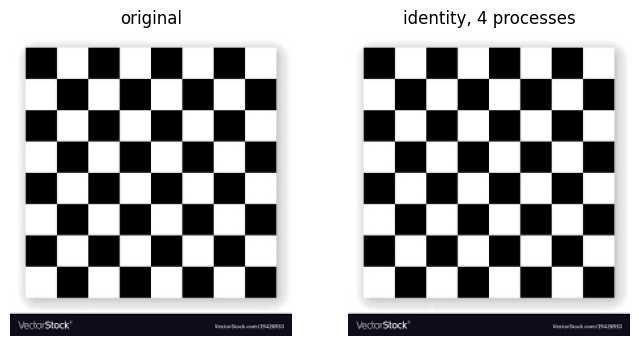

In [6]:
NUMPROCESS = 4

identity = image_filter("images/chess.jpg", MASKS["identity 5x5"], NUMPROCESS, 0, 0)
check("identity on images/chess.jpg == original", np.array_equal(identity, chess))

const128 = np.full((60, 80, 3), 128, dtype=np.uint8)
const250 = np.full((60, 80, 3), 250, dtype=np.uint8)
for is_conv in (0, 1):
    out = image_filter(const128, MASKS["mean 5x5"], NUMPROCESS, is_conv, 0)
    check(f"constant 128 + mean 5x5 -> all 128 (is_conv={is_conv})", np.all(out == 128))
    out = image_filter(const250, MASKS["sharpen"], NUMPROCESS, is_conv, 0)
    check(f"constant 250 + sharpen -> all 250 (is_conv={is_conv})", np.all(out == 250))

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(chess); ax[0].set_title("original")
ax[1].imshow(identity); ax[1].set_title("identity, 4 processes")
for a in ax: a.axis("off")
plt.show()

## Path input
The EVALUATION cells pass the path `F_IMAGE1` instead of an array.

In [7]:
F_IMAGE1 = "images/chess.jpg"
from_array = image_filter(chess, MASKS["gaussian 5x5"], 4, 0, 0)
check("str path == array input", np.array_equal(image_filter(F_IMAGE1, MASKS["gaussian 5x5"], 4, 0, 0), from_array))
check("pathlib.Path == array input", np.array_equal(image_filter(Path(F_IMAGE1), MASKS["gaussian 5x5"], 4, 0, 0), from_array))
check("path input == filter_sequential", np.array_equal(from_array, filter_sequential(chess, MASKS["gaussian 5x5"], 0, 0)))

OK   str path == array input


OK   pathlib.Path == array input


OK   path input == filter_sequential


## Invalid masks and invalid `numprocs`
All of these must raise `ValueError`.

In [8]:
def raises_value_error(f):
    try:
        f()
    except ValueError as e:
        print("   ValueError:", e)
        return True
    except Exception as e:
        print("   other exception:", type(e).__name__, e)
        return False
    print("   no exception")
    return False

bad_masks = {
    "2x2": np.ones((2, 2)),
    "4x4": np.ones((4, 4)),
    "7x7": np.ones((7, 7)),
    "3x6": np.ones((3, 6)),
    "1D":  np.ones(3),
    "3D":  np.ones((3, 3, 3)),
}
for name, m in bad_masks.items():
    check(f"invalid mask {name} -> ValueError", raises_value_error(lambda: image_filter(small, m, 2, 0, 0)))

for p in (0, -2, 2.5, "4", True):
    check(f"numprocs={p!r} -> ValueError", raises_value_error(lambda: image_filter(small, MASKS["mean 5x5"], p, 0, 0)))
check("parallel_filtering numprocs=0 -> ValueError",
      raises_value_error(lambda: parallel_filtering(small, MASKS["sobel"], MASKS["sharpen"], 0, 0, 0)))

   ValueError: The mask has 2 rows: it must be an odd number (1, 3 or 5).
OK   invalid mask 2x2 -> ValueError
   ValueError: The mask has 4 rows: it must be an odd number (1, 3 or 5).
OK   invalid mask 4x4 -> ValueError
   ValueError: The mask has 7 rows: the maximum is 5.
OK   invalid mask 7x7 -> ValueError
   ValueError: The mask has 6 columns: it must be an odd number (1, 3 or 5).
OK   invalid mask 3x6 -> ValueError
   ValueError: The mask must be 2D and has 1 dimensions.
OK   invalid mask 1D -> ValueError
   ValueError: The mask must be 2D and has 3 dimensions.
OK   invalid mask 3D -> ValueError
   ValueError: numprocs must be >= 1, got 0.
OK   numprocs=0 -> ValueError
   ValueError: numprocs must be >= 1, got -2.
OK   numprocs=-2 -> ValueError
   ValueError: numprocs must be an integer, got float.
OK   numprocs=2.5 -> ValueError
   ValueError: numprocs must be an integer, got str.
OK   numprocs='4' -> ValueError
   ValueError: numprocs must be an integer, got bool.
OK   numprocs=T

## `parallel_filtering` vs two `image_filter` calls
Same filters as in the CASCADE / PARALLEL FILTERING cells of the main notebook.

parallel_filtering: 0.54 s   two image_filter calls one after the other: 0.74 s
OK   parallel_filtering (path, conv, norm=1): result1 == image_filter(filter_h)
OK   parallel_filtering (path, conv, norm=1): result2 == image_filter(filter_v)


OK   parallel_filtering (array, corr, norm=0): result1 == image_filter(gaussian)


OK   parallel_filtering (array, corr, norm=0): result2 == image_filter(sharpen)


OK   parallel_filtering greyscale == filter_sequential


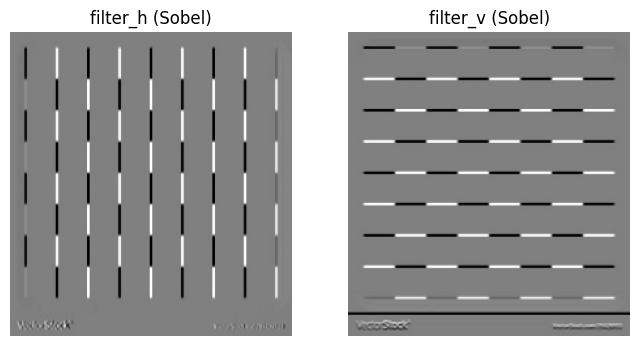

In [9]:
filter_h = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]])
filter_v = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])

t0 = time.time()
r1, r2 = parallel_filtering("images/chess.jpg", filter_h, filter_v, 4, 1, 1)
t_par = time.time() - t0

t0 = time.time()
s1 = image_filter("images/chess.jpg", filter_h, 4, 1, 1)
s2 = image_filter("images/chess.jpg", filter_v, 4, 1, 1)
t_seq = time.time() - t0
print(f"parallel_filtering: {t_par:.2f} s   two image_filter calls one after the other: {t_seq:.2f} s")

check("parallel_filtering (path, conv, norm=1): result1 == image_filter(filter_h)", np.array_equal(r1, s1))
check("parallel_filtering (path, conv, norm=1): result2 == image_filter(filter_v)", np.array_equal(r2, s2))

q1, q2 = parallel_filtering(chess, MASKS["gaussian 5x5"], MASKS["sharpen"], 2, 0, 0)
check("parallel_filtering (array, corr, norm=0): result1 == image_filter(gaussian)",
      np.array_equal(q1, image_filter(chess, MASKS["gaussian 5x5"], 2, 0, 0)))
check("parallel_filtering (array, corr, norm=0): result2 == image_filter(sharpen)",
      np.array_equal(q2, image_filter(chess, MASKS["sharpen"], 2, 0, 0)))

g1, g2 = parallel_filtering(grey, filter_h, filter_v, 2, 1, 1)
check("parallel_filtering greyscale == filter_sequential",
      np.array_equal(g1, filter_sequential(grey, filter_h, 1, 1)) and np.array_equal(g2, filter_sequential(grey, filter_v, 1, 1)))

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(r1); ax[0].set_title("filter_h (Sobel)")
ax[1].imshow(r2); ax[1].set_title("filter_v (Sobel)")
for a in ax: a.axis("off")
plt.show()

## Timing and speed-up
Mean 5x5 on `images/chess.jpg` with 1, 2, 4 and 8 processes (best of 3 runs).
Speed-up = T(1 process) / T(p processes). The time includes creating the Pool and
the shared memory, so the speed-up is below the ideal line.

In [10]:
mask = MASKS["mean 5x5"]
PROCS = [1, 2, 4, 8]
REPEATS = 3

t0 = time.perf_counter()
filter_sequential(chess, mask, 0, 0)
t_ref = time.perf_counter() - t0
print(f"filter_sequential (Part A, no Pool): {t_ref:.3f} s")

times = []
for p in PROCS:
    runs = []
    for _ in range(REPEATS):
        t0 = time.perf_counter()
        image_filter("images/chess.jpg", mask, p, 0, 0)
        runs.append(time.perf_counter() - t0)
    times.append(min(runs))

speedup = [times[0] / t for t in times]
print(f"{'procs':>5} {'time (s)':>9} {'speed-up':>9} {'efficiency':>10}")
for p, t, s in zip(PROCS, times, speedup):
    print(f"{p:>5} {t:>9.3f} {s:>9.2f} {s / p:>10.2f}")

filter_sequential (Part A, no Pool): 0.774 s


procs  time (s)  speed-up efficiency
    1     0.916      1.00       1.00
    2     0.618      1.48       0.74
    4     0.480      1.91       0.48
    8     0.603      1.52       0.19


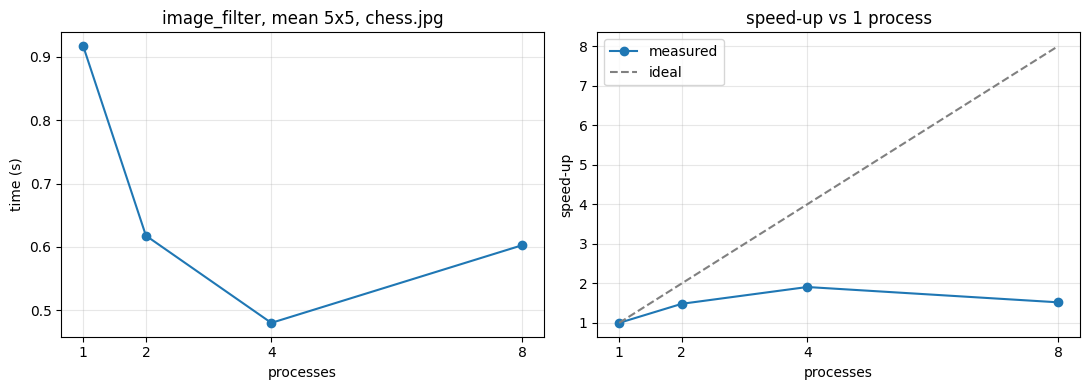

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(PROCS, times, "o-")
ax[0].set_xlabel("processes"); ax[0].set_ylabel("time (s)")
ax[0].set_title("image_filter, mean 5x5, chess.jpg"); ax[0].set_xticks(PROCS); ax[0].grid(alpha=0.3)

ax[1].plot(PROCS, speedup, "o-", label="measured")
ax[1].plot(PROCS, PROCS, "--", color="grey", label="ideal")
ax[1].set_xlabel("processes"); ax[1].set_ylabel("speed-up")
ax[1].set_title("speed-up vs 1 process"); ax[1].set_xticks(PROCS); ax[1].grid(alpha=0.3); ax[1].legend()
plt.tight_layout()
plt.show()

## Summary

In [12]:
failed = [name for name, ok in checks.items() if not ok]
print(f"{len(checks) - len(failed)}/{len(checks)} checks passed")
for name in failed:
    print("FAILED:", name)
assert not failed, "some checks failed"
print("ALL CHECKS TRUE")

29/29 checks passed
ALL CHECKS TRUE
